# Mood-Controlled Automatic Music Generator
**Core topic:** Automatic Music Generation  
**Model:** Mood-conditioned LSTM  
**Dataset:** MAESTRO MIDI  
**Environment:** Google Colab (GPU recommended)

This notebook extends a symbolic piano-music generator with selectable mood and tempo.

## Important research note
MAESTRO is a piano-performance dataset and does **not** provide reliable mood labels for every performance. This prototype creates **weak mood labels** from musical features (tempo, note density, pitch range, and estimated major/minor mode). These labels are approximate heuristics, not ground-truth human emotion labels. The model learns associations in those labels; it does not truly understand emotion.

Run cells from top to bottom. The first run uses a limited subset to keep prototyping practical. Results from this subset are for development, not final scientific claims.

## 1. Install dependencies

In [1]:
%pip -q install pretty_midi mido tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 59.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.6/54.6 kB 5.4 MB/s eta 0:00:00


## 2. Imports, reproducibility, and project folders

In [2]:
import os, glob, json, pickle, random, math, warnings, urllib.request, zipfile
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import pretty_midi

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

PROJECT_DIR = "/content/mood_music_generator"
RAW_DIR = os.path.join(PROJECT_DIR, "data", "raw")
MIDI_DIR = os.path.join(RAW_DIR, "maestro")
PROCESSED_DIR = os.path.join(PROJECT_DIR, "data", "processed")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
OUTPUT_DIR = os.path.join(PROJECT_DIR, "outputs")
for folder in [RAW_DIR, MIDI_DIR, PROCESSED_DIR, MODEL_DIR, OUTPUT_DIR]:
    os.makedirs(folder, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
print("Project directory:", PROJECT_DIR)

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Project directory: /content/mood_music_generator


## 3. Download and extract MAESTRO MIDI archive

In [4]:
import os
import glob
import zipfile
import urllib.request

DATA_URL = (
    "https://storage.googleapis.com/magentadata/datasets/"
    "maestro/v3.0.0/maestro-v3.0.0-midi.zip"
)

ZIP_PATH = os.path.join(RAW_DIR, "maestro-v3.0.0-midi.zip")

os.makedirs(RAW_DIR, exist_ok=True)
os.makedirs(MIDI_DIR, exist_ok=True)

# Download the archive
if not os.path.exists(ZIP_PATH) or os.path.getsize(ZIP_PATH) < 1_000_000:
    if os.path.exists(ZIP_PATH):
        os.remove(ZIP_PATH)

    print("Downloading MAESTRO MIDI archive...")
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)

print("Archive size (MB):", round(os.path.getsize(ZIP_PATH) / 1e6, 2))

# Verify the downloaded archive
if not zipfile.is_zipfile(ZIP_PATH):
    raise RuntimeError(
        "Invalid ZIP file. Delete the archive and retry the download."
    )

# Extract and inspect archive contents
with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    names = zf.namelist()

    midi_members = [
        name for name in names
        if name.lower().endswith((".mid", ".midi"))
    ]

    print("Archive entries:", len(names))
    print("MIDI files inside archive:", len(midi_members))

    if not midi_members:
        print("Sample archive entries:", names[:20])
        raise FileNotFoundError(
            "The ZIP contains no MIDI files. Check the download URL."
        )

    zf.extractall(MIDI_DIR)

# Find MIDI files recursively
midi_files = sorted(
    glob.glob(os.path.join(MIDI_DIR, "**", "*.mid"), recursive=True)
    + glob.glob(os.path.join(MIDI_DIR, "**", "*.midi"), recursive=True)
)

if not midi_files:
    print("Extracted folders:", os.listdir(MIDI_DIR)[:30])
    raise FileNotFoundError(
        "MIDI files exist in the ZIP but were not found after extraction."
    )

print("MIDI files found:", len(midi_files))
print("Examples:", midi_files[:5])

Archive size (MB): 58.42
Archive entries: 1280
MIDI files inside archive: 1276
MIDI files found: 1276
Examples: ['/content/mood_music_generator/data/raw/maestro/maestro-v3.0.0/2004/MIDI-Unprocessed_SMF_02_R1_2004_01-05_ORIG_MID--AUDIO_02_R1_2004_05_Track05_wav.midi', '/content/mood_music_generator/data/raw/maestro/maestro-v3.0.0/2004/MIDI-Unprocessed_SMF_02_R1_2004_01-05_ORIG_MID--AUDIO_02_R1_2004_06_Track06_wav.midi', '/content/mood_music_generator/data/raw/maestro/maestro-v3.0.0/2004/MIDI-Unprocessed_SMF_02_R1_2004_01-05_ORIG_MID--AUDIO_02_R1_2004_08_Track08_wav.midi', '/content/mood_music_generator/data/raw/maestro/maestro-v3.0.0/2004/MIDI-Unprocessed_SMF_02_R1_2004_01-05_ORIG_MID--AUDIO_02_R1_2004_10_Track10_wav.midi', '/content/mood_music_generator/data/raw/maestro/maestro-v3.0.0/2004/MIDI-Unprocessed_SMF_05_R1_2004_01_ORIG_MID--AUDIO_05_R1_2004_02_Track02_wav.midi']


## 4. Extract musical features and create weak mood labels

The following rules are intentionally simple and transparent:
- **Energetic:** faster tempo and/or high note density
- **Calm:** slower tempo and lower note density
- **Happy:** estimated major mode with moderate-to-fast tempo
- **Sad:** estimated minor mode with slower-to-moderate tempo
- **Suspenseful:** remaining pieces with high pitch range or high note density

These are heuristics for a prototype. They can mislabel music. For stronger research, replace them with human-annotated mood labels or validate the labels with listeners.

In [5]:
MOODS = ["happy", "sad", "calm", "energetic", "suspenseful"]
MOOD_TO_ID = {m: i for i, m in enumerate(MOODS)}
ID_TO_MOOD = {i: m for m, i in MOOD_TO_ID.items()}

def estimate_major_mode(midi_obj):
    # Very rough pitch-class heuristic; not a reliable music-theory key detector.
    pcs = np.zeros(12, dtype=np.float64)
    for inst in midi_obj.instruments:
        if inst.is_drum:
            continue
        for note in inst.notes:
            pcs[note.pitch % 12] += max(0.05, note.end - note.start)
    if pcs.sum() == 0:
        return True
    major_profile = np.array([6.35, 2.23, 3.48, 2.33, 4.38, 4.09, 2.52, 5.19, 2.39, 3.66, 2.29, 2.88])
    minor_profile = np.array([6.33, 2.68, 3.52, 5.38, 2.60, 3.53, 2.54, 4.75, 3.98, 2.69, 3.34, 3.17])
    scores = []
    for profile in [major_profile, minor_profile]:
        scores.append(max(np.corrcoef(np.roll(profile, shift), pcs)[0, 1]
                          for shift in range(12) if np.std(pcs) > 0))
    return scores[0] >= scores[1]

def get_features_and_mood(midi_path):
    midi_obj = pretty_midi.PrettyMIDI(midi_path)
    notes = [n for inst in midi_obj.instruments if not inst.is_drum for n in inst.notes]
    if len(notes) < 20:
        return None
    duration = max(midi_obj.get_end_time(), 1.0)
    tempo = float(np.median(midi_obj.get_tempo_changes()[1])) if len(midi_obj.get_tempo_changes()[1]) else 110.0
    density = len(notes) / duration
    pitches = np.array([n.pitch for n in notes])
    major = estimate_major_mode(midi_obj)
    pitch_range = float(np.percentile(pitches, 90) - np.percentile(pitches, 10))
    # Transparent, hand-designed weak-label rules.
    if tempo >= 125 or density >= 3.5:
        mood = "energetic"
    elif tempo <= 78 and density <= 2.5:
        mood = "calm"
    elif major and tempo >= 95:
        mood = "happy"
    elif (not major) and tempo <= 115:
        mood = "sad"
    else:
        mood = "suspenseful" if pitch_range >= 24 or density >= 2.8 else ("calm" if tempo < 100 else "happy")
    return {"path": midi_path, "tempo": tempo, "density": density,
            "pitch_range": pitch_range, "major_estimate": bool(major),
            "mood": mood, "mood_id": MOOD_TO_ID[mood], "duration": duration,
            "note_count": len(notes)}

MAX_FILES = 300  # Increase only after the prototype runs successfully
random.shuffle(midi_files)
selected_files = midi_files[:min(MAX_FILES, len(midi_files))]
records, failed = [], []
for path in tqdm(selected_files, desc="Extracting features"):
    try:
        row = get_features_and_mood(path)
        if row is not None:
            records.append(row)
    except Exception as exc:
        failed.append((path, str(exc)))

if len(records) < 20:
    raise RuntimeError("Too few usable MIDI files. Check the download and try again.")
print("Usable files:", len(records), "| failed:", len(failed))
print(Counter(r["mood"] for r in records))
with open(os.path.join(PROCESSED_DIR, "mood_labels.json"), "w") as f:
    json.dump([{k: (v if not isinstance(v, np.generic) else v.item()) for k, v in r.items() if k != "path"} for r in records], f, indent=2)

Extracting features:   0%|          | 0/300 [00:00<?, ?it/s]

Usable files: 300 | failed: 0
Counter({'energetic': 300})


## 5. Convert MIDI to event tokens

In [6]:
TIME_STEP = 0.1
MAX_TIME_SHIFT = 50
VELOCITY_BINS = 8

def velocity_bin(velocity):
    return min(max((int(velocity) - 1) // 16, 0), VELOCITY_BINS - 1)

def midi_to_events(midi_path):
    midi_obj = pretty_midi.PrettyMIDI(midi_path)
    raw_events = []
    for instrument in midi_obj.instruments:
        if instrument.is_drum:
            continue
        for note in instrument.notes:
            start = max(0.0, round(note.start / TIME_STEP) * TIME_STEP)
            end = max(round(note.end / TIME_STEP) * TIME_STEP, start + TIME_STEP)
            raw_events.append((start, 1, f"VELOCITY_{velocity_bin(note.velocity)}"))
            raw_events.append((start, 2, f"NOTE_ON_{note.pitch}"))
            raw_events.append((end, 0, f"NOTE_OFF_{note.pitch}"))
    if not raw_events:
        return []
    raw_events.sort(key=lambda item: (item[0], item[1]))
    events, previous_time = [], 0.0
    for timestamp, priority, token in raw_events:
        delta = max(0, round((timestamp - previous_time) / TIME_STEP))
        while delta > 0:
            shift = min(delta, MAX_TIME_SHIFT)
            events.append(f"TIME_SHIFT_{shift}")
            delta -= shift
        events.append(token)
        previous_time = timestamp
    return events

for row in records:
    try:
        row["events"] = midi_to_events(row["path"])
    except Exception:
        row["events"] = []
records = [r for r in records if len(r["events"]) > 100]
print("Files with usable event sequences:", len(records))
print("Example events:", records[0]["events"][:20])

Files with usable event sequences: 300
Example events: ['TIME_SHIFT_10', 'VELOCITY_3', 'NOTE_ON_73', 'TIME_SHIFT_1', 'VELOCITY_2', 'VELOCITY_2', 'VELOCITY_2', 'VELOCITY_2', 'VELOCITY_2', 'NOTE_ON_64', 'NOTE_ON_61', 'NOTE_ON_68', 'NOTE_ON_44', 'NOTE_ON_37', 'TIME_SHIFT_4', 'NOTE_OFF_64', 'TIME_SHIFT_1', 'NOTE_OFF_61', 'TIME_SHIFT_1', 'NOTE_OFF_68']


## 6. Build vocabulary and train/validation split

In [7]:
rng = np.random.default_rng(SEED)
indices = np.arange(len(records))
rng.shuffle(indices)
n_val = max(1, int(0.15 * len(indices)))
val_set = set(indices[:n_val].tolist())
train_records = [r for i, r in enumerate(records) if i not in val_set]
val_records = [r for i, r in enumerate(records) if i in val_set]

counts = Counter(token for row in train_records for token in row["events"])
vocabulary = sorted(counts)
event_to_id = {event: i for i, event in enumerate(vocabulary)}
id_to_event = {i: event for event, i in event_to_id.items()}
vocab_size = len(vocabulary)

SEQUENCE_LENGTH = 100
STRIDE = 10

def make_windows(rows):
    xs, ys, moods = [], [], []
    for row in rows:
        ids = [event_to_id[t] for t in row["events"] if t in event_to_id]
        mood_id = row["mood_id"]
        for start in range(0, len(ids) - SEQUENCE_LENGTH, STRIDE):
            xs.append(ids[start:start + SEQUENCE_LENGTH])
            ys.append(ids[start + SEQUENCE_LENGTH])
            moods.append(mood_id)
    if not xs:
        raise RuntimeError("No training windows. Increase MAX_FILES or reduce SEQUENCE_LENGTH.")
    return (np.asarray(xs, dtype=np.int32),
            np.asarray(ys, dtype=np.int32),
            np.asarray(moods, dtype=np.int32))

X_train, y_train, m_train = make_windows(train_records)
X_val, y_val, m_val = make_windows(val_records)
print("Train:", X_train.shape, y_train.shape, m_train.shape)
print("Validation:", X_val.shape, y_val.shape, m_val.shape)
print("Vocabulary:", vocab_size)
print("Mood IDs:", MOOD_TO_ID)

Train: (487306, 100) (487306,) (487306,)
Validation: (121670, 100) (121670,) (121670,)
Vocabulary: 234
Mood IDs: {'happy': 0, 'sad': 1, 'calm': 2, 'energetic': 3, 'suspenseful': 4}


## 7. Build a mood-conditioned LSTM

The model receives two inputs:
1. The last 100 musical event tokens
2. A mood ID (one of the five weak-label categories)

The mood embedding is concatenated with the sequence representation before predicting the next event.

In [8]:
EMBEDDING_DIM = 128
LSTM_UNITS = 256
MOOD_EMBED_DIM = 16

event_input = keras.Input(shape=(SEQUENCE_LENGTH,), dtype="int32", name="event_sequence")
mood_input = keras.Input(shape=(), dtype="int32", name="mood_id")

x = layers.Embedding(vocab_size, EMBEDDING_DIM, name="event_embedding")(event_input)
x = layers.LSTM(LSTM_UNITS, return_sequences=True)(x)
x = layers.Dropout(0.3)(x)
x = layers.LSTM(LSTM_UNITS)(x)

m = layers.Embedding(len(MOODS), MOOD_EMBED_DIM, name="mood_embedding")(mood_input)
combined = layers.Concatenate()([x, m])
combined = layers.Dense(128, activation="relu")(combined)
combined = layers.Dropout(0.25)(combined)
output = layers.Dense(vocab_size, activation="softmax", name="next_event")(combined)

model = keras.Model(inputs={"event_sequence": event_input, "mood_id": mood_input},
                    outputs=output, name="mood_conditioned_music_lstm")
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["sparse_categorical_accuracy"])
model.summary()

Model: "mood_conditioned_music_lstm"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ event_sequence      │ (None, 100)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ event_embedding     │ (None, 100, 128)  │     29,952 │ event_sequence[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 100, 256)  │    394,240 │ event_embedding[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 100, 256)  │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mood_id             │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 256)       │    525,312 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mood_embedding      │ (None, 16)        │         80 │ mood_id[0][0]     │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 272)       │          0 │ lstm_1[0][0],     │
│ (Concatenate)       │                   │            │ mood_embedding[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │     34,944 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ next_event (Dense)  │ (None, 234)       │     30,186 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,014,714 (3.87 MB)

 Trainable params: 1,014,714 (3.87 MB)

 Non-trainable params: 0 (0.00 B)

## 8. Train the model

In [9]:
EPOCHS = 10
BATCH_SIZE = 64
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(os.path.join(MODEL_DIR, "best_mood_music_lstm.keras"),
                                    monitor="val_loss", save_best_only=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5)
]
history = model.fit(
    {"event_sequence": X_train, "mood_id": m_train}, y_train,
    validation_data=({"event_sequence": X_val, "mood_id": m_val}, y_val),
    epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=callbacks, verbose=1
)
model.save(os.path.join(MODEL_DIR, "mood_music_lstm_final.keras"))
print("Model saved.")

Epoch 1/10
7615/7615 ━━━━━━━━━━━━━━━━━━━━ 192s 24ms/step - loss: 3.0780 - sparse_categorical_accuracy: 0.2519 - val_loss: 2.7302 - val_sparse_categorical_accuracy: 0.2886 - learning_rate: 0.0010
Epoch 2/10
7615/7615 ━━━━━━━━━━━━━━━━━━━━ 220s 29ms/step - loss: 2.6061 - sparse_categorical_accuracy: 0.3062 - val_loss: 2.3962 - val_sparse_categorical_accuracy: 0.3581 - learning_rate: 0.0010
Epoch 3/10
7615/7615 ━━━━━━━━━━━━━━━━━━━━ 201s 26ms/step - loss: 2.3823 - sparse_categorical_accuracy: 0.3592 - val_loss: 2.2061 - val_sparse_categorical_accuracy: 0.4045 - learning_rate: 0.0010
Epoch 4/10
7615/7615 ━━━━━━━━━━━━━━━━━━━━ 192s 25ms/step - loss: 2.2374 - sparse_categorical_accuracy: 0.3916 - val_loss: 2.0923 - val_sparse_categorical_accuracy: 0.4272 - learning_rate: 0.0010
Epoch 5/10
7615/7615 ━━━━━━━━━━━━━━━━━━━━ 192s 25ms/step - loss: 2.1396 - sparse_categorical_accuracy: 0.4109 - val_loss: 2.0185 - val_sparse_categorical_accuracy: 0.4395 - learning_rate: 0.0010
Epoch 6/10
7615/7615 ━━━━

## 9. Plot training curves

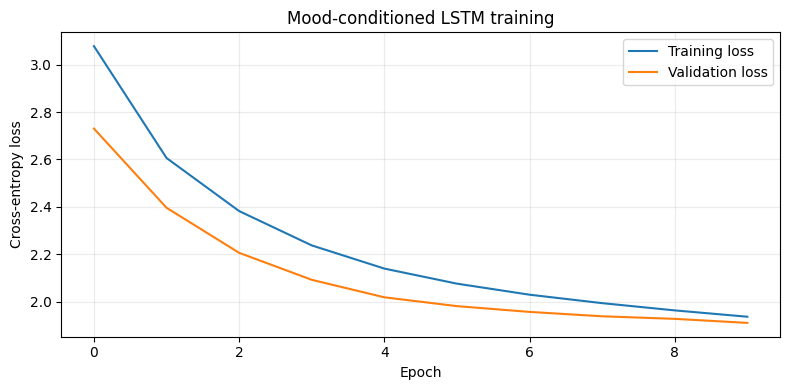

In [10]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Cross-entropy loss")
plt.title("Mood-conditioned LSTM training")
plt.legend(); plt.grid(alpha=0.25); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "training_loss.png"), dpi=160)
plt.show()

## 10. Generate music for a selected mood and tempo

In [11]:
def sample_next_token(probabilities, temperature=0.8):
    probabilities = np.asarray(probabilities, dtype=np.float64)
    probabilities = np.clip(probabilities, 1e-12, 1.0)
    logits = np.log(probabilities) / max(float(temperature), 1e-3)
    logits -= np.max(logits)
    probs = np.exp(logits)
    probs /= probs.sum()
    return int(np.random.choice(len(probs), p=probs))

def generate_event_ids(model, seed_ids, mood_id, num_new_events=500, temperature=0.8):
    context = list(seed_ids[-SEQUENCE_LENGTH:])
    if len(context) < SEQUENCE_LENGTH:
        raise ValueError("Seed must contain at least SEQUENCE_LENGTH event tokens.")
    generated = []
    for _ in tqdm(range(num_new_events), desc="Generating"):
        x = np.asarray(context[-SEQUENCE_LENGTH:], dtype=np.int32)[None, :]
        m = np.asarray([mood_id], dtype=np.int32)
        probs = model.predict({"event_sequence": x, "mood_id": m}, verbose=0)[0]
        next_id = sample_next_token(probs, temperature)
        generated.append(next_id)
        context.append(next_id)
    return [id_to_event[i] for i in generated]

# Select a seed from a held-out piece. Mood is supplied separately to the model.
seed_row = max(val_records, key=lambda r: len([t for t in r["events"] if t in event_to_id]))
seed_ids = [event_to_id[t] for t in seed_row["events"] if t in event_to_id]
print("Seed piece's weak mood label:", seed_row["mood"])
print("Available moods:", MOODS)

Seed piece's weak mood label: energetic
Available moods: ['happy', 'sad', 'calm', 'energetic', 'suspenseful']


## 11. Convert generated events to MIDI

In [12]:
def events_to_midi(events, output_path, tempo_bpm=100):
    pm = pretty_midi.PrettyMIDI(initial_tempo=float(tempo_bpm))
    instrument = pretty_midi.Instrument(
        program=pretty_midi.instrument_name_to_program("Acoustic Grand Piano"))
    current_time = 0.0
    velocity = 80
    active_notes = {}
    completed_notes = []
    for event in events:
        if event.startswith("TIME_SHIFT_"):
            current_time += int(event.rsplit("_", 1)[1]) * TIME_STEP
        elif event.startswith("VELOCITY_"):
            level = int(event.rsplit("_", 1)[1])
            velocity = int(np.clip((level + 0.5) * 127 / VELOCITY_BINS, 1, 127))
        elif event.startswith("NOTE_ON_"):
            pitch = int(event.rsplit("_", 1)[1])
            active_notes.setdefault(pitch, []).append((current_time, velocity))
        elif event.startswith("NOTE_OFF_"):
            pitch = int(event.rsplit("_", 1)[1])
            queue = active_notes.get(pitch, [])
            if queue:
                start_time, note_velocity = queue.pop(0)
                if current_time > start_time:
                    completed_notes.append(pretty_midi.Note(
                        velocity=note_velocity, pitch=pitch, start=start_time, end=current_time))
    final_time = max(current_time, 1.0)
    for pitch, starts in active_notes.items():
        for start_time, note_velocity in starts:
            completed_notes.append(pretty_midi.Note(
                velocity=note_velocity, pitch=pitch, start=start_time,
                end=max(final_time, start_time + TIME_STEP)))
    instrument.notes = sorted(completed_notes, key=lambda n: (n.start, n.pitch))
    pm.instruments.append(instrument)
    pm.write(output_path)
    return pm

def generate_mood_music(mood="calm", tempo_bpm=90, num_events=500, temperature=0.8):
    if mood not in MOOD_TO_ID:
        raise ValueError(f"Mood must be one of: {MOODS}")
    events = generate_event_ids(model, seed_ids, MOOD_TO_ID[mood],
                                num_new_events=num_events, temperature=temperature)
    safe_mood = mood.replace(" ", "_")
    out_path = os.path.join(OUTPUT_DIR, f"generated_{safe_mood}_{tempo_bpm}bpm.mid")
    pm = events_to_midi(events, out_path, tempo_bpm=tempo_bpm)
    print("Saved MIDI:", out_path)
    print("Generated events:", len(events))
    print("Reconstructed notes:", sum(len(i.notes) for i in pm.instruments))
    print("Duration (seconds):", round(pm.get_end_time(), 2))
    return out_path, pm, events

# Example generation. Change mood and tempo to experiment.
generated_path, generated_pm, generated_events = generate_mood_music(
    mood="calm", tempo_bpm=90, num_events=500, temperature=0.8
)

Generating:   0%|          | 0/500 [00:00<?, ?it/s]

Saved MIDI: /content/mood_music_generator/outputs/generated_calm_90bpm.mid
Generated events: 500
Reconstructed notes: 153
Duration (seconds): 7.3


## 12. Visualize generated music

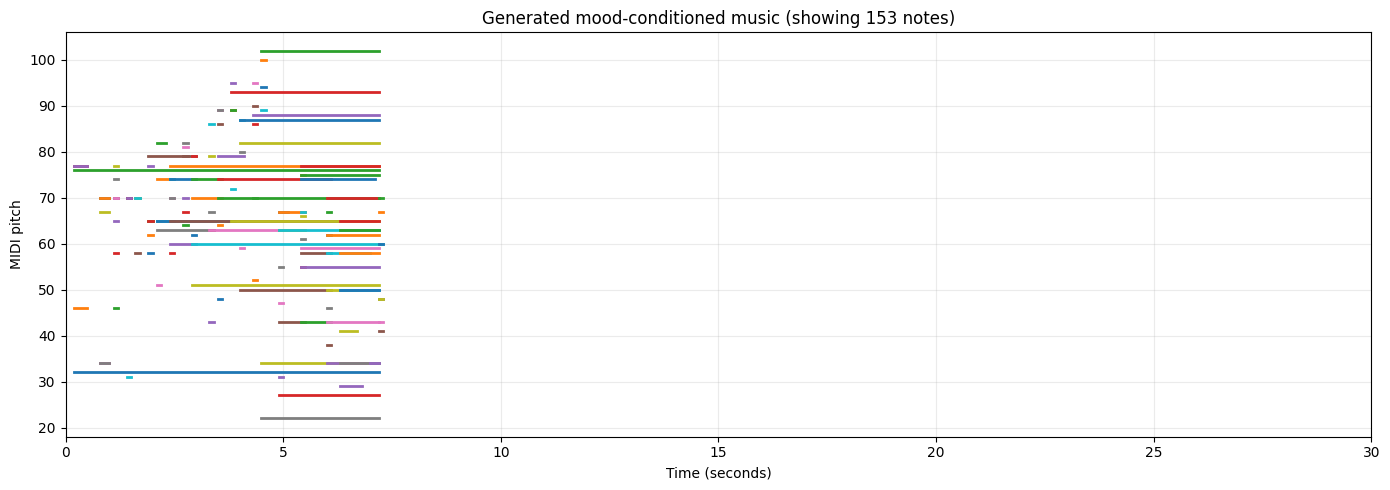

Download the MIDI from the Colab file browser at: /content/mood_music_generator/outputs/generated_calm_90bpm.mid


In [13]:
def plot_piano_roll(midi_obj, max_seconds=30, title="Generated piano roll"):
    plt.figure(figsize=(14, 5))
    plotted = 0
    for inst in midi_obj.instruments:
        if inst.is_drum:
            continue
        for note in inst.notes:
            if note.start <= max_seconds:
                plt.plot([note.start, min(note.end, max_seconds)], [note.pitch, note.pitch], linewidth=2)
                plotted += 1
    plt.xlabel("Time (seconds)"); plt.ylabel("MIDI pitch")
    plt.title(f"{title} (showing {plotted} notes)")
    plt.xlim(0, max_seconds); plt.grid(alpha=0.25); plt.tight_layout()
    plt.show()

plot_piano_roll(generated_pm, title="Generated mood-conditioned music")
print("Download the MIDI from the Colab file browser at:", generated_path)

## 13. Evaluate next-event prediction and save metrics

In [14]:
val_loss, val_accuracy = model.evaluate(
    {"event_sequence": X_val, "mood_id": m_val}, y_val,
    batch_size=BATCH_SIZE, verbose=0
)
metrics = {
    "validation_loss": float(val_loss),
    "validation_next_event_accuracy": float(val_accuracy),
    "generated_event_count": int(len(generated_events)),
    "reconstructed_midi_notes": int(sum(len(i.notes) for i in generated_pm.instruments)),
    "reconstructed_midi_duration_seconds": float(generated_pm.get_end_time()),
    "mood_labels_are_heuristic": True,
    "mood_categories": MOODS
}
metrics_path = os.path.join(OUTPUT_DIR, "evaluation_metrics.json")
with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=2)
print(json.dumps(metrics, indent=2))

{
  "validation_loss": 1.9105490446090698,
  "validation_next_event_accuracy": 0.46086955070495605,
  "generated_event_count": 500,
  "reconstructed_midi_notes": 153,
  "reconstructed_midi_duration_seconds": 7.299999999999997,
  "mood_labels_are_heuristic": true,
  "mood_categories": [
    "happy",
    "sad",
    "calm",
    "energetic",
    "suspenseful"
  ]
}


## 14. Optional: generate another mood

Try multiple moods at the same tempo and compare the outputs. Because labels are heuristic and this is a small prototype, the mood difference may be subtle or inconsistent. Listen to several generated samples and validate results rather than assuming the label guarantees a perceived emotion.

In [15]:
# Examples (run one at a time)
# happy_path, happy_pm, happy_events = generate_mood_music("happy", tempo_bpm=115)
# sad_path, sad_pm, sad_events = generate_mood_music("sad", tempo_bpm=75)
# energetic_path, energetic_pm, energetic_events = generate_mood_music("energetic", tempo_bpm=140)
# suspense_path, suspense_pm, suspense_events = generate_mood_music("suspenseful", tempo_bpm=100)

## 15. Next step: Streamlit interface

After verifying that training and MIDI generation work in Colab, build a separate Streamlit app that loads `mood_music_lstm_final.keras`, the event vocabulary, and the generation functions. The web app can expose mood, tempo, duration/event count, and download controls. Keep the notebook as the training pipeline.

### Limitations to mention in a report
- Mood labels are weak heuristic labels, not human-annotated ground truth.
- The current model generates symbolic MIDI events, not raw audio.
- Changing MIDI tempo alone changes speed, not necessarily emotional character.
- Evaluate several samples per mood and, ideally, conduct a small listener study before making strong claims about mood control.
- The default file limit is for prototyping; report the actual dataset size, runtime, and measured results.